# 08 · Robustez de los resultados

Se reestiman las pruebas de H2 y H3 bajo siete especificaciones alternativas (500 remuestras bootstrap y 500 permutaciones en cada una):

| Especificación | Qué cambia | Por qué |
|---|---|---|
| **Principal** | IPC, tendencia OLS, 4 componentes por dimensión, sin atípicos monetarios | Especificación de referencia |
| **2 y 3 componentes** | Cada dimensión entra con 2 o 3 componentes | Que el resultado no dependa del número de componentes elegido |
| **Deflactor** | Variable dependiente: deflactor del PIB | Otra medida de inflación; incluye Argentina, Cuba, Somalia y Turkmenistán |
| **Mediana anual** | Nivel medido con la mediana en lugar de la media | Evitar que un año de crisis determine el nivel (solo cambia la media) |
| **Theil-Sen** | Tendencia estimada con pendiente robusta | Evitar que un solo año extremo determine la tendencia (solo cambia la tendencia) |
| **Con atípicos** | Se reincorporan los 9 atípicos monetarios | Evaluar si la exclusión determina los resultados |
| **Control + tasas nominales** | Se suman las tasas de interés nominales al control monetario | Prueba de estrés: ¿sobrevive H3 a un control monetario que contiene la inflación esperada? |

La robustez de H1 frente a la configuración de clustering está en el notebook 06 (sección 5), y la de H3 frente al tratamiento de los casos extremos, en el notebook 03 (sección 5).

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from inflacion.config import Paths, load_params
from inflacion.viz import CATEGORICAL, CLUSTER_COLORS, DIM_LABELS, DIMENSION_COLORS, apply_theme, heatmap, show, subtitle
from inflacion.viz.theme import DIVERGING, INK_MUTED, INK_SECONDARY, SEQUENTIAL_BLUE

apply_theme()
P = load_params()
D = Paths.processed
pd.set_option("display.precision", 3)
VAR = {"": "Principal", "_k2": "2 componentes", "_k3": "3 componentes", "_deflactor": "Deflactor", "_mediana": "Mediana anual",
       "_theil_sen": "Theil-Sen", "_con_atipicos": "Con atípicos", "_tasas_nominales": "Control + tasas nominales"}
STAT = {"media": "Media", "tendencia": "Tendencia", "volatilidad": "Volatilidad"}
rows = []
for suf, name in VAR.items():
    for hip in ["h2", "h3"]:
        d = pd.read_csv(D / f"reg_{hip}{suf}.csv").assign(especificacion=name, hip=hip.upper())
        rows.append(d)
R = pd.concat(rows)
R["prueba"] = R["hip"] + " · " + R["estadistico"].map(STAT) + " · " + R["bloque"].map(lambda b: DIM_LABELS.get(b, "No monetarias"))
for suf, name in VAR.items():
    d = pd.read_csv(D / f"reg_diagnosticos{suf}.csv")
    print(f"{name:26s} n = {d['n'].iloc[0]} · predictores del modelo B: {int(d.loc[d['modelo'] == 'B', 'k'].iloc[0])}")

Principal                  n = 167 · predictores del modelo B: 16
2 componentes              n = 167 · predictores del modelo B: 8
3 componentes              n = 167 · predictores del modelo B: 12
Deflactor                  n = 173 · predictores del modelo B: 16
Mediana anual              n = 167 · predictores del modelo B: 16
Theil-Sen                  n = 167 · predictores del modelo B: 16
Con atípicos               n = 173 · predictores del modelo B: 16
Control + tasas nominales  n = 167 · predictores del modelo B: 18


## 1. Solidez de cada prueba en las ocho especificaciones

Una prueba se considera **sólida** si su p HC3 corregido por Holm es menor que 0,05, su p de permutación es menor que 0,05 y el límite inferior del IC 95% del ΔR² ajustado es mayor que 0. Es **indicio** si alguna prueba sin corregir da p < 0,05. La cifra en cada celda es el p HC3 corregido por Holm.

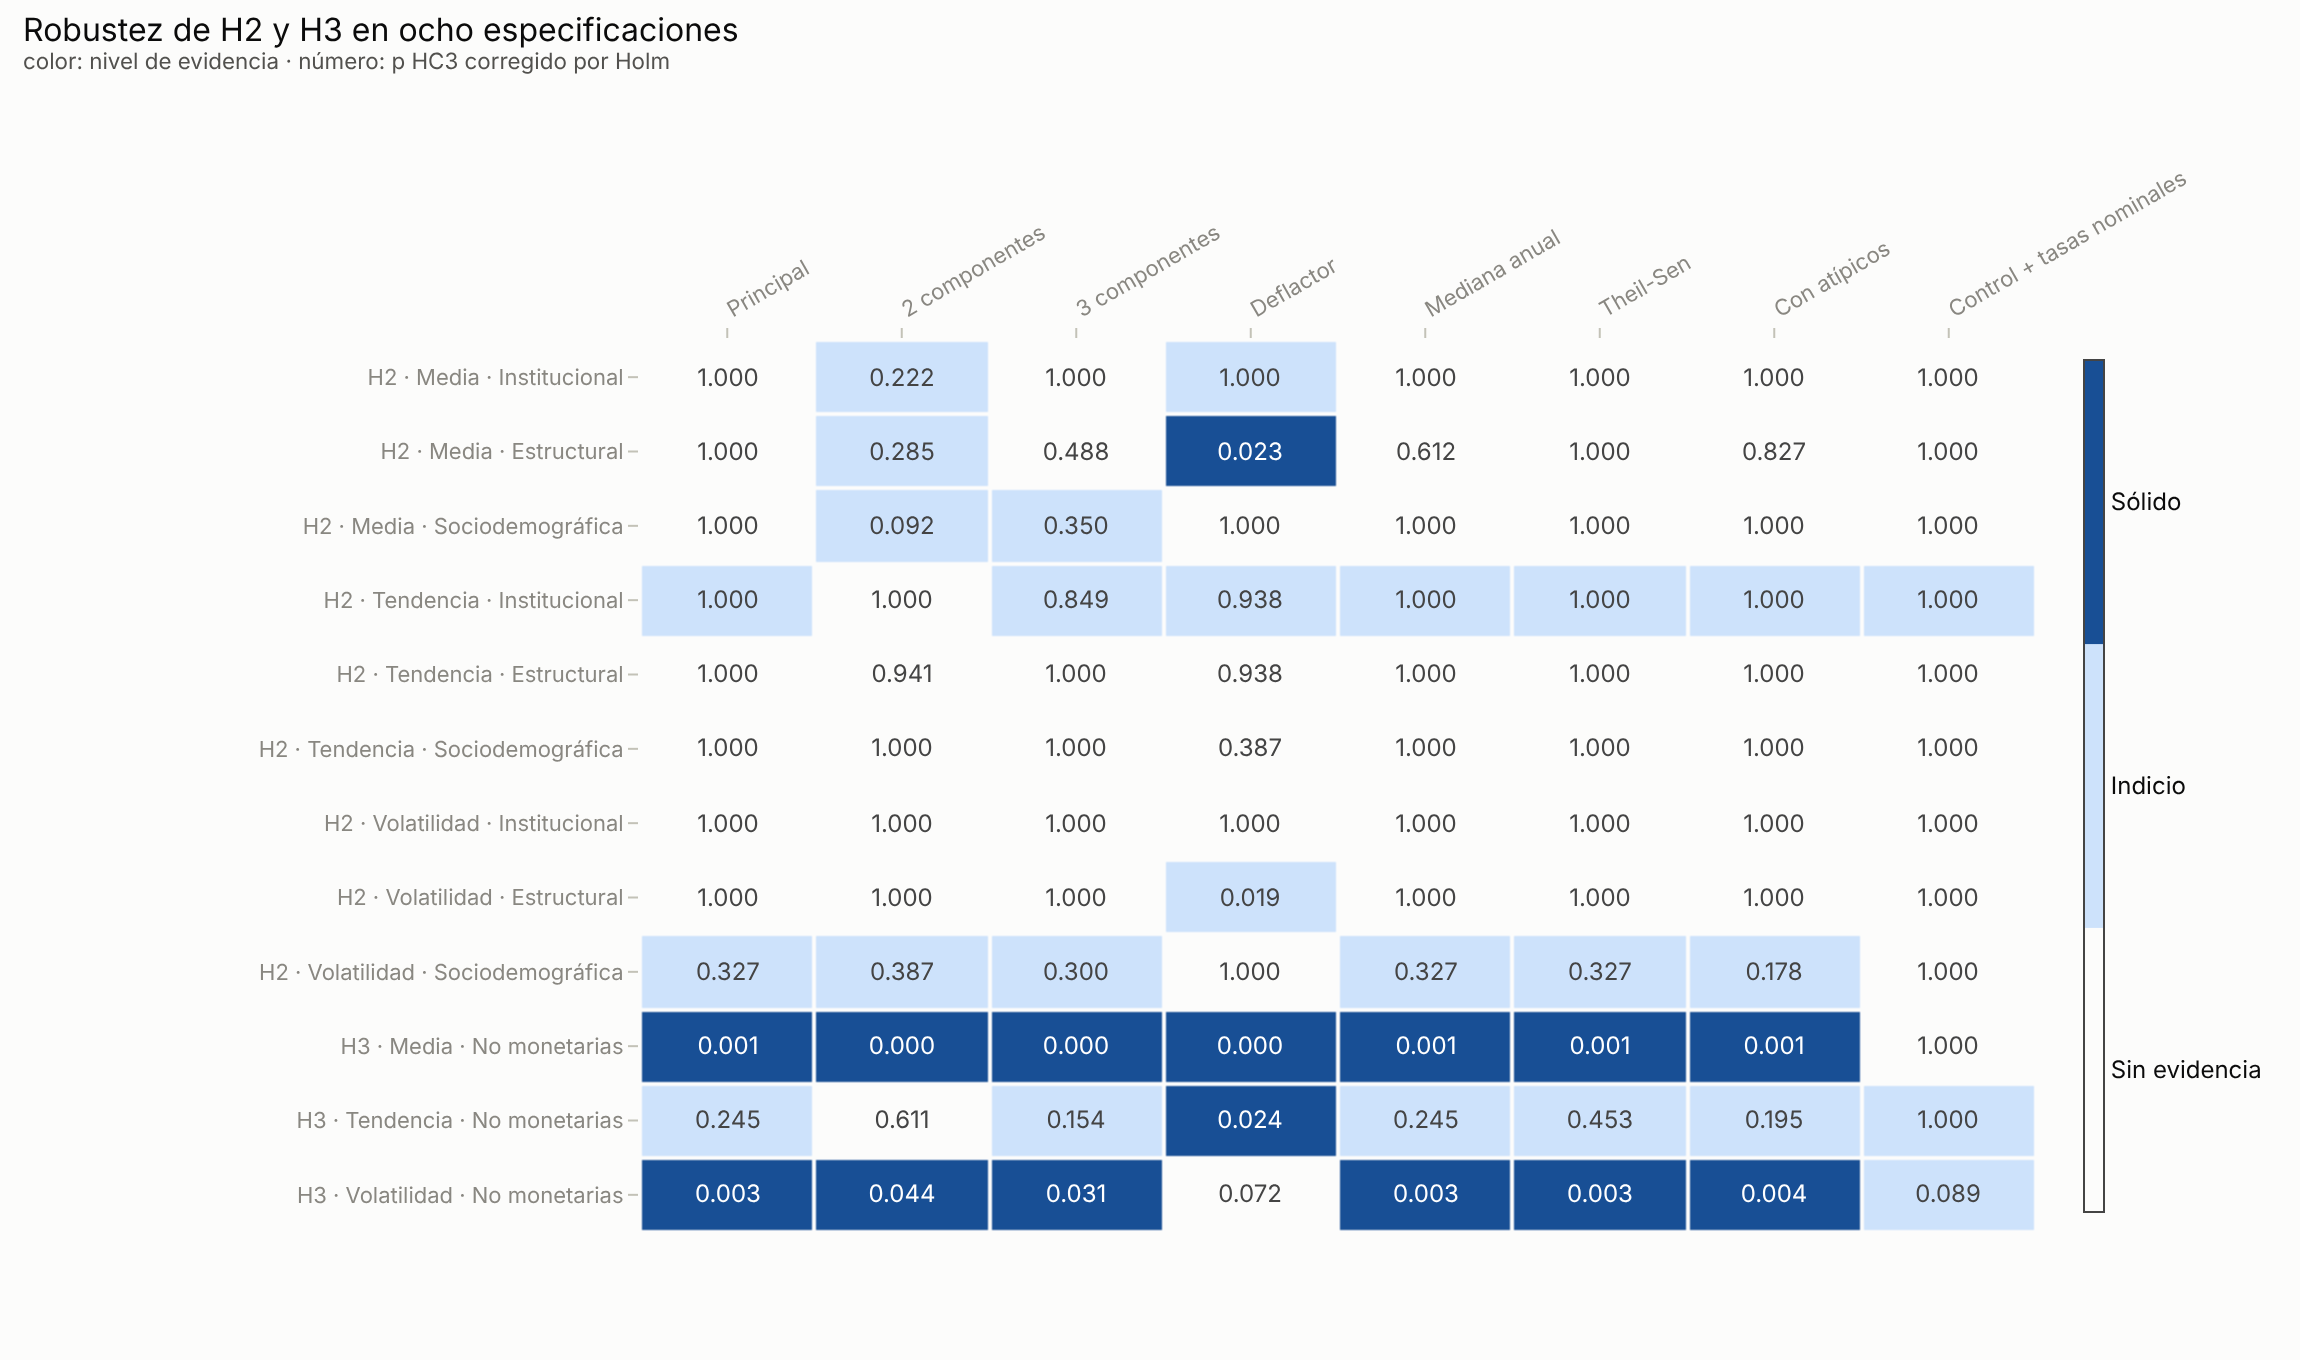

especificacion,Principal,2 componentes,3 componentes,Deflactor,Mediana anual,Theil-Sen,Con atípicos,Control + tasas nominales
prueba,,,,,,,,
H2 · Media · Institucional,—,indicio,—,indicio,—,—,—,—
H2 · Media · Estructural,—,indicio,—,sólido,—,—,—,—
H2 · Media · Sociodemográfica,—,indicio,indicio,—,—,—,—,—
H2 · Tendencia · Institucional,indicio,—,indicio,indicio,indicio,indicio,indicio,indicio
H2 · Tendencia · Estructural,—,—,—,—,—,—,—,—
H2 · Tendencia · Sociodemográfica,—,—,—,—,—,—,—,—
H2 · Volatilidad · Institucional,—,—,—,—,—,—,—,—
H2 · Volatilidad · Estructural,—,—,—,indicio,—,—,—,—
H2 · Volatilidad · Sociodemográfica,indicio,indicio,indicio,—,indicio,indicio,indicio,—


In [2]:
R["nivel"] = np.where(R["solido"], 2, np.where(R[["p", "p_HC3", "p_permutacion"]].min(axis=1) < 0.05, 1, 0))
order = R.drop_duplicates("prueba")["prueba"].tolist()
M = R.pivot(index="prueba", columns="especificacion", values="nivel").loc[order, list(VAR.values())]
Pp = R.pivot(index="prueba", columns="especificacion", values="p_HC3_holm").loc[order, list(VAR.values())]
cs = [[0, "#fcfcfb"], [0.333, "#fcfcfb"], [0.334, "#cde2fb"], [0.666, "#cde2fb"], [0.667, "#184f95"], [1, "#184f95"]]
fig = go.Figure(go.Heatmap(z=M.values, x=list(M.columns), y=list(M.index), zmin=-0.5, zmax=2.5, colorscale=cs,
                           text=Pp.map(lambda v: f"{v:.3f}").values, texttemplate="%{text}", xgap=2, ygap=2,
                           hovertemplate="%{y} · %{x}: p Holm %{text}<extra></extra>",
                           colorbar=dict(tickvals=[0, 1, 2], ticktext=["Sin evidencia", "Indicio", "Sólido"], thickness=10)))
fig.update_layout(title=subtitle("Robustez de H2 y H3 en ocho especificaciones", "color: nivel de evidencia · número: p HC3 corregido por Holm"),
                  xaxis=dict(side="top", showgrid=False, tickangle=-30), yaxis=dict(autorange="reversed", showgrid=False), margin=dict(l=320, t=170))
show(fig, "08_robustez_matriz", width=1150, height=680)
M.replace({2: "sólido", 1: "indicio", 0: "—"})

**Interpretación.**

- **H3 para la media es sólida en siete de las ocho especificaciones**: con 2, 3 o 4 componentes, con el deflactor, con la mediana, con Theil-Sen y con los atípicos. Es la conclusión más estable del análisis.
- **La excepción es la prueba de estrés con tasas nominales.** Si se suman las tasas de interés nominales al control monetario, el R² ajustado del modelo monetario sube de 0,27 a 0,57 y la mejora de las otras dimensiones desaparece (p Holm = 1). No es sorprendente: por el efecto Fisher, la tasa nominal media de un país es aproximadamente su inflación media más una tasa real, así que ese control casi contiene la variable dependiente. Por eso las tasas quedan fuera de la especificación principal. Pero el resultado obliga a leer H3 como una asociación condicionada a esa decisión, y no como un efecto que sobrevive a cualquier control monetario.
- **H3 para la volatilidad es sólida en seis de las ocho** (todas salvo el deflactor y la de tasas nominales).
- **H3 para la tendencia** es sólida solo con el deflactor. La tendencia del deflactor está más expuesta a los términos de intercambio (notebook 03), así que este resultado no se generaliza.
- **H2** solo es sólida en un caso aislado: la dimensión estructural sobre la media con el deflactor. Ninguna dimensión aporta por sí sola de forma estable.

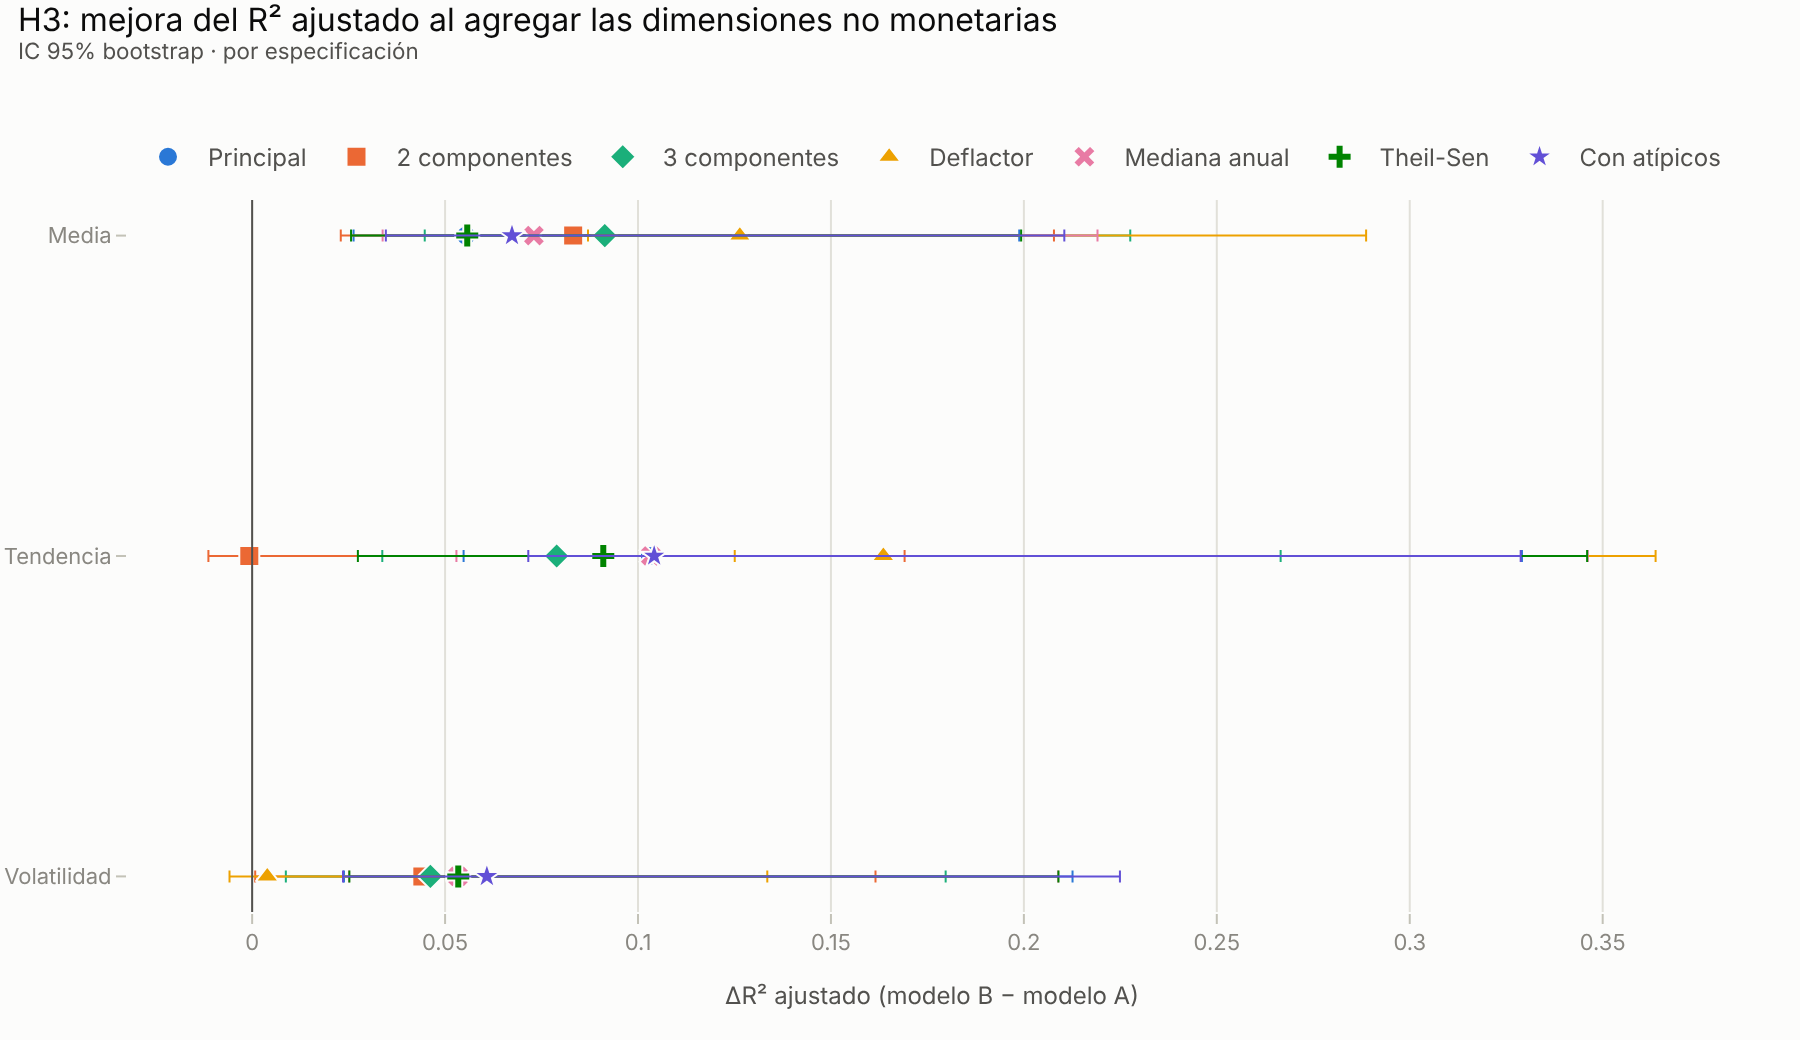

r2adj_restringido                        \
estadistico                           media tendencia volatilidad   
especificacion                                                      
Principal                             0.274     0.030       0.306   
2 componentes                         0.240    -0.006       0.314   
3 componentes                         0.245     0.002       0.311   
Deflactor                             0.207     0.078       0.387   
Mediana anual                         0.229     0.030       0.306   
Theil-Sen                             0.274     0.042       0.306   
Con atípicos                          0.243     0.006       0.293   
Control + tasas nominales             0.571     0.394       0.538   

                          r2adj_completo                           f2  \
estadistico                        media tendencia volatilidad  media   
especificacion                                                          
Principal                          0.330     0.133       0.360  0.170   
2 componentes                      0.323    -0.006       0.358  0.166   
3 componentes                      0.336     0.081       0.357  0.204   
Deflactor                          0.333     0.242       0.391  0.281   
Mediana anual                      0.302     0.133       0.360  0.193   
Theil-Sen                          0.330     0.133       0.360  0.170   
Con atípicos                       0.311     0.110       0.354  0.182   
Control + tasas nominales          0.563     0.437       0.550  0.061   

                                                p_HC3_holm            \
estadistico               tendencia volatilidad      media tendencia   
especificacion                                                         
Principal                     0.209       0.170      0.001     0.245   
2 componentes                 0.037       0.109      0.000     0.611   
3 componentes                 0.149       0.135      0.000     0.154   
Deflactor                     0.309       0.084      0.000     0.024   
Mediana anual                 0.209       0.170      0.001     0.245   
Theil-Sen                     0.193       0.170      0.001     0.453   
Con atípicos                  0.203       0.178      0.001     0.195   
Control + tasas nominales     0.165       0.111      1.000     1.000   

                                       
estadistico               volatilidad  
especificacion                         
Principal                       0.003  
2 componentes                   0.044  
3 componentes                   0.031  
Deflactor                       0.072  
Mediana anual                   0.003  
Theil-Sen                       0.003  
Con atípicos                    0.004  
Control + tasas nominales       0.089

In [3]:
h3 = R[R["hip"] == "H3"]
specs = [s for s in VAR.values() if s != "Control + tasas nominales"]
fig = go.Figure()
for i, spec in enumerate(specs):
    g = h3[h3["especificacion"] == spec]
    fig.add_scatter(x=g["delta_r2adj"], y=g["estadistico"].map(STAT), mode="markers", name=spec,
                    marker=dict(size=10, color=CATEGORICAL[i % len(CATEGORICAL)], symbol=["circle", "square", "diamond", "triangle-up", "x", "cross", "star"][i]),
                    error_x=dict(type="data", symmetric=False, array=g["delta_ic95_sup"] - g["delta_r2adj"], arrayminus=g["delta_r2adj"] - g["delta_ic95_inf"],
                                 color=CATEGORICAL[i % len(CATEGORICAL)], thickness=1, width=3),
                    hovertemplate=spec + " · %{y}: ΔR² aj. %{x:.3f}<extra></extra>")
fig.add_vline(x=0, line=dict(color=INK_SECONDARY, width=1))
fig.update_layout(scattermode="group", title=subtitle("H3: mejora del R² ajustado al agregar las dimensiones no monetarias", "IC 95% bootstrap · por especificación"),
                  xaxis=dict(title="ΔR² ajustado (modelo B − modelo A)"), yaxis=dict(showgrid=False, autorange="reversed"))
show(fig, "08_h3_delta_r2", height=520)
h3.pivot(index="especificacion", columns="estadistico", values=["r2adj_restringido", "r2adj_completo", "f2", "p_HC3_holm"]).round(3).loc[list(VAR.values())]

**Interpretación.** En la media, el modelo con las cuatro dimensiones mejora el R² ajustado entre 0,06 y 0,13 según la especificación, con f² entre 0,17 y 0,28 (efecto mediano) e intervalos bootstrap que excluyen el cero. La mejora más grande aparece con el deflactor, que incluye a más países de inflación alta. Reincorporar los atípicos no cambia ninguna conclusión: su exclusión no está produciendo los resultados. Con tasas nominales en el control, en cambio, la mejora es nula en los tres estadísticos.

## 2. Comparación con la versión 1 (tesis entregada)

La tesis original reportó estos resultados (sección 4 del documento). La tabla los contrasta con los obtenidos ahora, tras reconstruir el pipeline completo.

In [4]:
h1 = pd.read_csv(D / "h1_tests.csv").set_index("estadistico")["eta2_transformado"]
h3p = R[(R["hip"] == "H3") & (R["especificacion"] == "Principal")].set_index("estadistico")
ok_media = int(R[(R["hip"] == "H3") & (R["estadistico"] == "media")]["solido"].sum())
cmp = pd.DataFrame({
    "Tesis v1": ["Respaldada (dispersión intra-grupo alta; GMM tied k=4)",
                 "No confirmada (ninguna dimensión robusta en clásico, bootstrap y HC3)",
                 "Parcial: solo volatilidad (R² aj. 0,274 → 0,329)"],
    "Pipeline reconstruido": [f"Respaldada: el grupo explica {h1['media']:.0%} (media), {h1['tendencia']:.0%} (tendencia) y {h1['volatilidad']:.0%} (volatilidad); robusta a la configuración (K-means k=5)",
                              "No respaldada: ninguna dimensión aporta por sí sola de forma estable (un caso aislado con el deflactor)",
                              f"Parcial: media (R² aj. {h3p.loc['media', 'r2adj_restringido']:.2f} → {h3p.loc['media', 'r2adj_completo']:.2f}".replace(".", ",") + f", sólida en {ok_media} de {len(VAR)} especificaciones) y volatilidad; sin mejora predictiva fuera de muestra"],
}, index=["H1", "H2", "H3"])
cmp

,Tesis v1,Pipeline reconstruido
H1,Respaldada (dispersión intra-grupo alta; GMM t...,"Respaldada: el grupo explica 25% (media), 1% (..."
H2,No confirmada (ninguna dimensión robusta en cl...,No respaldada: ninguna dimensión aporta por sí...
H3,"Parcial: solo volatilidad (R² aj. 0,274 → 0,329)","Parcial: media (R² aj, 0,27 → 0,33, sólida en ..."


**Por qué cambian los resultados.** Los cambios en H2 y H3 se deben a correcciones del pipeline, no a variaciones aleatorias:

1. **Fuga de información (precios)**: en la v1, el IPC, los deflactores y los índices de precios estaban entre las variables monetarias que forman los perfiles y los predictores. En la v2 se excluyen todos.
2. **Fuga de información (tasas de interés)**: la tasa de interés real se calcula restando la inflación del deflactor, y las nominales incorporan la inflación esperada. Se excluyen de las features; las nominales se usan solo como prueba de estrés.
3. **Comparabilidad**: la v1 conservaba niveles absolutos (totales en US$ o moneda local, poblaciones, conteos) fuera del bloque monetario, y series per cápita en moneda local, cuyo crecimiento nominal incluye la inflación. La v2 los excluye en todas las dimensiones.
4. **Duplicados**: el mismo índice WGI en dos escalas pesaba doble en el PCA institucional.
5. **Transformación de la media**: log(1 + media/100) casi no corregía la asimetría (4,7 → 4,2). log(media) la lleva a 0,3.
6. **Bloques balanceados**: cada dimensión entra en las regresiones con el mismo número de componentes. Con la regla anterior (30% de la varianza) el control monetario tenía 2 componentes y la estructural 4, lo que favorecía artificialmente a la estructural en H2.
7. **Cobertura de la inflación**: se exige el 60% de los años, igual que a las features.
8. **Datos**: WDI se descargó en su versión de octubre de 2026 y la clasificación se rehízo íntegramente con Groq.

Durante la reconstrucción, los resultados de H2 cambiaron con cada corrección (la evidencia estructural apareció con bloques desbalanceados y desapareció al igualarlos). **H3 para la media fue el único resultado que se mantuvo en todas las versiones.** Esa sensibilidad de H2 es en sí misma un hallazgo: con 167 países y dimensiones muy colineales, la atribución a una dimensión específica es frágil.

## 3. Limitaciones

- **Selección de la muestra por disponibilidad de datos.** Faltan justamente los casos más extremos: Argentina (IPC solo 2018-2020), Venezuela después de 2016, Zimbabue y Sudán del Sur con series cortas. La especificación con el deflactor recupera parte de ellos y confirma H3 para la media.
- **Asociación, no predicción.** La mejora de H3 dentro de muestra casi no se traslada a la predicción fuera de muestra (notebook 07, sección 3). Los resultados describen diferencias entre países; no sirven para pronosticar la inflación de un país.
- **Dependencia del control monetario.** H3 desaparece si el control monetario incluye las tasas de interés nominales. La decisión de excluirlas está justificada (contienen la inflación esperada), pero el resultado es condicional a ella.
- **Pérdida de información temporal.** Resumir 21 años en tres estadísticos descarta la dinámica (secuencia, rezagos). Los resultados describen asociaciones entre perfiles de largo plazo, no relaciones dinámicas ni causales.
- **Clasificación por LLM.** Coincide 88% con la clasificación manual y 95% con la de la tesis, pero las fronteras entre dimensiones (fiscal-monetaria, empleo) son discutibles. En particular, la regla de "variables fiscales en sentido amplio" lleva el gasto público en salud al bloque monetario, y con él parte del gradiente de desarrollo.
- **Colinealidad entre dimensiones.** Los primeros componentes de las cuatro dimensiones comparten un gradiente de desarrollo (|r| hasta 0,9; VIF máximo 19,6 en el modelo completo). Eso vuelve imprecisos los coeficientes individuales y frágil la atribución a dimensiones específicas.
- **Estructura de grupos débil.** Las silhouettes bajas (≤ 0,27) indican que los perfiles monetario-fiscales forman un continuo. Los grupos son una partición útil, no tipos naturales.

## 4. Extensiones posibles

1. **Panel dinámico**: modelar la inflación año a año con efectos fijos y las dimensiones como moderadoras, en lugar de resumir las trayectorias.
2. **Variable dependiente con más cobertura**: completar Argentina y Venezuela con fuentes alternativas (FMI WEO, institutos provinciales) y documentar el empalme.
3. **Codebook V3**: acotar la regla fiscal al gasto y financiamiento agregados, y validarla contra una muestra nueva clasificada a mano antes de ver la salida del modelo.
4. **Modelos regularizados sobre los indicadores originales** (elastic net con validación cruzada anidada) como contraste del enfoque PCA + OLS; la validación con ridge del notebook 07 es un primer paso en esa dirección.